<a href="https://colab.research.google.com/github/speediedan/interpretune/blob/main/src/it_examples/notebooks/publish/gradient_readouts/gradient_readouts.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" />
</a>

# Gradient readouts: what a gradient is taken of, and what editing it means

A gradient intervention edits the gradient of one scalar while a backward pass runs. Until recently that scalar was
fixed: the last-token logit of some target ids. A **readout** lets you choose it. It is a function of the logits and of
activations read at named sites in the same forward pass, so the scalar can be a logit difference, the projection of an
intermediate activation onto a probe direction, or a sparse autoencoder (SAE) feature's activation.

This notebook asks one question of GPT-2 small, on the prompt *"The Louvre museum is in the city of"*: **where does
the model's evidence for Paris come from?** It answers it three ways:

1. **A probe readout beside a logit readout.** Where, by layer and position, does each readout draw its gradient
   from, and where do the two disagree?
2. **A latent feature readout.** Which earlier positions does a Paris-selective SAE feature's gradient come from,
   checked against forward ablations so the gradient map is not taken on trust?
3. **A gradient edit, read correctly.** What does removing the probe direction from the gradient at one site change
   upstream, and what does such an edit mean (it is not a change of readout)?

Everything runs on CPU in well under a minute after the model loads. Requirements:
`uv pip install -e ".[examples]" --group git-deps` (sae-lens is pinned in the `git-deps` group).

> **Until the `speediedan/rte` component is public (#261), this notebook needs a Hugging Face token with access to
> it** (set `HF_TOKEN`). The session it builds supplies GPT-2 small and its SAE through the same configuration the
> other examples use; the prompts here are our own.

In [2]:
# Parameters - These will be injected by papermill during parameterized test runs
TARGET = "The Louvre museum is in the city of"  # the prompt the three moves analyze; must be one of the Paris prompts
READ_LAYER = 9  # the probe and the SAE feature both read the residual stream entering this block
ABLATION_LAYER = 4  # where move 2 compares the feature's gradient with forward ablations
EDIT_LAYER = 5  # where move 3 edits the gradient
REVISION = None  # component snapshot; None resolves the recorded pin (a local-publish rev validates unmerged configs)

In [4]:
# @title Imports { display-mode: "form" }
import os

import interpretune as it
import interpretune.analysis  # noqa: F401  (registers the it.<op> wrappers)
import matplotlib.pyplot as plt
import torch
from interpretune import ITSession, ITSessionConfig, SAELensFromPretrainedConfig
from interpretune.analysis.backends import Readout, get_model_backend

from it_examples.seeds import ensure_local_seeds

torch.manual_seed(0)

src/interpretune/hub/trust.py:96: Refusing to execute analysis ops from 'speediedan/jlens_steering_ops': loading it runs code published by that repo inside this process, with your filesystem, network and Hugging Face token. Interpretune does not execute hub-resident code unless you opt in.
  Inspect it first: interpretune.hub.pull('speediedan/jlens_steering_ops') caches the repo without executing anything, so you can read the entrypoint the manifest names.
  Then opt in for this session: os.environ['IT_TRUST_REMOTE_CODE'] = '1' (or export IT_TRUST_REMOTE_CODE=1 before starting the process).
  Pin a revision when you pull so trusted code cannot change under you.
  Details: https://interpretune.org/en/latest/usage/hub_trust_posture.html
src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'ct_feature_intervention' already has an assigned op or alias so the alias specified by 'feature_intervention_forward' cannot be mapped to it
src/interpretune/analysis/ops/dispatcher.py:1110: Alias '

## Setup

Build a session from the `speediedan/rte` component's GPT-2 SAELens configuration, attaching one residual SAE
(`gpt2-small-res-jb`, at the input of block `READ_LAYER`) on CPU. Loading a component runs the Python code it
publishes, so Interpretune refuses until you opt in; `it.hub.pull` caches the repository without executing anything,
so you can read the entrypoint first.

We use three things from the session: the model (a TransformerLens `TransformerBridge`), its model backend, which
runs gradient interventions, and the attached SAE. The bridge runs in compatibility mode (TransformerLens' weight
processing), because the SAE was trained on a processed model; the last line of the setup cell checks that the SAE
reconstructs this model's residual stream, since a mismatch there fails silently.

In [5]:
# @title Session { display-mode: "form" }
ensure_local_seeds()  # idempotent, offline: seed publish sources -> local components cache
if REVISION is None:  # a validation run passes a local-publish REVISION and needs neither fetch
    it.hub.pull("speediedan/rte")  # caches the component's manifest and entrypoint; executes nothing
    it.hub.pull("speediedan/rte", "rte_demo.gpt2.sae_lens")  # fetches the one configuration loaded below
os.environ["IT_TRUST_REMOTE_CODE"] = "1"  # opt in to running the component's entrypoint, for this session only
itdm_cfg, it_cfg, dm_cls, m_cls = it.hub.load("speediedan/rte", "rte_demo.gpt2.sae_lens", revision=REVISION)
it_cfg.sae_cfgs = [
    SAELensFromPretrainedConfig(release="gpt2-small-res-jb", sae_id=f"blocks.{READ_LAYER}.hook_resid_pre", device="cpu")
]
# The SAE was trained on GPT-2 with TransformerLens' weight processing (its metadata asks for center_writing_weights),
# and the configuration's bridge runs the raw weights, on which this SAE explains none of the residual stream. Without
# this line every feature below would be read off the wrong stream, with no error (#1050).
it_cfg.tl_cfg.enable_compatibility_mode = True
session = ITSession(
    ITSessionConfig(
        adapter_ctx=(it.Adapter.core, it.Adapter.sae_lens),
        datamodule_cfg=itdm_cfg,
        module_cfg=it_cfg,
        datamodule_cls=dm_cls,
        module_cls=m_cls,
    )
)
module = session.module
model = module.model  # a TransformerBridge over GPT-2 small
backend = get_model_backend(module)
sae = module.sae_handles[0]
print(f"{type(model).__name__}, {model.cfg.n_layers} blocks, backend {type(backend).__name__}")
print(f"SAE at {sae.cfg.metadata.hook_name}")
with torch.no_grad():  # the SAE must reconstruct the stream it is read on, or its features mean nothing here
    hook_name = sae.cfg.metadata.hook_name
    _, cache = model.run_with_cache(model.to_tokens("The capital of France is"), names_filter=[hook_name])
    stream = cache[hook_name][0, 1:]
    residual = stream - sae.decode(sae.encode(stream))
    explained = 1 - (residual**2).sum() / ((stream - stream.mean(0)) ** 2).sum()
print(f"SAE explained variance on a held-out prompt: {explained.item():.2f}")
assert explained > 0.5, "the SAE does not reconstruct this residual stream; check the bridge's weight processing"

src/interpretune/hub/components.py:568: 'speediedan/rte' resolved to the local-publish snapshot localf06e432, which shadows the cached Hub revision(s) ['14d388e1b6a2', '22152f0e349b', '4db2f48ce89f', '67fff0a10dd0', '738e41229e39', '7d0bbe4d887c', '8f61b54c4d2c', 'a9b2407a96e5']; the Hub was not consulted (resolution is cache-only). If you meant the published artifact, run interpretune.hub.pull('speediedan/rte') or resolve with require_hub=True.


src/interpretune/adapters/sae_lens/config.py:305: This SAEConfig's device type ('cuda') does not match the configured TL device ('cpu'). Setting the device type for this SAE to match the specified TL device ('cpu').


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[INFO] interpretune.utils.logging: Enabling TransformerBridge compatibility mode with kwargs: {}


[INFO] interpretune.utils.logging: Moving SAETransformerBridge to device: cpu


Moving model to device:  cpu


~/.venvs/it_1032/lib/python3.13/site-packages/sae_lens/saes/sae.py:254: UserWarning: 
This SAE has non-empty model_from_pretrained_kwargs. 
For optimal performance, load the model like so:
model = HookedSAETransformer.from_pretrained_no_processing(..., **cfg.model_from_pretrained_kwargs)
  warnings.warn(
[INFO] interpretune.utils.logging: Attempted to clean a key that was not present, continuing without cleaning that key: 'GPT2Config' object has no attribute 'quantization_config'


[INFO] interpretune.utils.logging: Attempted to clean a key that was not present, continuing without cleaning that key: 'GPT2Config' object has no attribute '_pre_quantization_dtype'


SAETransformerBridge, 12 blocks, backend TLModelBackend
SAE at blocks.9.hook_resid_pre
SAE explained variance on a held-out prompt: 0.80


### The prompts

Five prompts whose answer is Paris and five whose answer is London. The target prompt is analyzed; the others fit the
probe and select the SAE feature. GPT-2 small is a small model and does not know every one of these (the logit
difference below says which it does), which is why the target is one it gets clearly right.

In [6]:
# @title Prompts and the model's answers { display-mode: "form" }
PARIS_PROMPTS = [
    "The Eiffel Tower is in the city of",
    "The Louvre museum is in the city of",
    "Notre-Dame cathedral is in the city of",
    "The Arc de Triomphe is in the city of",
    "The Champs-Élysées is in the city of",
]
LONDON_PROMPTS = [
    "Big Ben is in the city of",
    "Buckingham Palace is in the city of",
    "Westminster Abbey is in the city of",
    "Trafalgar Square is in the city of",
    "The Tower Bridge is in the city of",
]
assert TARGET in PARIS_PROMPTS, "the target is held out of the Paris prompts that fit the probe, so it must be one"
PARIS, LONDON = model.to_single_token(" Paris"), model.to_single_token(" London")
# The residual stream entering block READ_LAYER, read as block READ_LAYER - 1's output: the same tensor, at a hook point
# the SAE does not replace. The pinned sae-lens leaves the SAE's own hook point stale once a pass with the SAE spliced
# in has run, so a later pass reading it there fails (fixed in later sae-lens releases; #652 moves to one).
READ = f"blocks.{READ_LAYER - 1}.hook_out"


def last_token_residual(prompt):
    _, cache = model.run_with_cache(model.to_tokens(prompt), names_filter=[READ])
    return cache[READ][0, -1]


with torch.no_grad():
    for prompt in PARIS_PROMPTS + LONDON_PROMPTS:
        logits = model(model.to_tokens(prompt))[0, -1]
        diff = (logits[PARIS] - logits[LONDON]).item()
        top = model.to_string(logits.argmax())
        print(f"{prompt:<40} logit(Paris) - logit(London) {diff:+6.2f}   top token {top!r}")

tokens = model.to_tokens(TARGET)
str_tokens = model.to_str_tokens(TARGET)
batch = {"input": tokens}
print("\ntarget tokens:", str_tokens)

The Eiffel Tower is in the city of       logit(Paris) - logit(London)  -0.16   top token ' London'
The Louvre museum is in the city of      logit(Paris) - logit(London)  +4.78   top token ' Paris'


Notre-Dame cathedral is in the city of   logit(Paris) - logit(London)  +2.29   top token ' Paris'
The Arc de Triomphe is in the city of    logit(Paris) - logit(London)  +4.38   top token ' Paris'


The Champs-Élysées is in the city of     logit(Paris) - logit(London)  +5.54   top token ' Paris'
Big Ben is in the city of                logit(Paris) - logit(London)  -1.27   top token ' New'


Buckingham Palace is in the city of      logit(Paris) - logit(London)  -3.70   top token ' London'
Westminster Abbey is in the city of      logit(Paris) - logit(London)  -4.38   top token ' London'


Trafalgar Square is in the city of       logit(Paris) - logit(London)  -0.91   top token ' London'
The Tower Bridge is in the city of       logit(Paris) - logit(London)  -2.38   top token ' Toronto'

target tokens: ['<|endoftext|>', 'The', ' Lou', 'vre', ' museum', ' is', ' in', ' the', ' city', ' of']


## 1. A probe readout beside a logit readout

**Question.** The model says Paris. Is that decision assembled from the same evidence a mid-layer "Paris versus
London" representation is built from?

**The probe.** The difference of the mean residual streams at the last token (entering block `READ_LAYER`) between
the Paris and London prompts, with the target held out, normalized to unit length. A difference-of-means direction is
the simplest linear probe there is, and on ten prompts it is less prone to overfit than a fitted classifier.

**Two readouts.** Each is a `Readout`: `fn(logits, activations)` returning a scalar, with `activations` holding the
activation at each site the readout names, from the same forward pass the backward pass starts from.

- `logit difference`: $\text{logit}(\text{Paris}) - \text{logit}(\text{London})$ at the last token, a function of the
  logits only.
- `probe`: the last token's residual stream at `READ` projected onto the probe direction. No function of the logits
  can express it.

In [7]:
# @title Fit the probe and define the two readouts { display-mode: "form" }
with torch.no_grad():
    paris_mean = torch.stack([last_token_residual(p) for p in PARIS_PROMPTS if p != TARGET]).mean(0)
    london_mean = torch.stack([last_token_residual(p) for p in LONDON_PROMPTS]).mean(0)
    direction = (paris_mean - london_mean) / (paris_mean - london_mean).norm()
    print("projection onto the probe direction (held-out target marked *):")
    for prompt in PARIS_PROMPTS + LONDON_PROMPTS:
        mark = "*" if prompt == TARGET else " "
        print(f"  {mark} {prompt:<40} {(last_token_residual(prompt) @ direction).item():+7.2f}")


def logit_difference(logits, activations):
    return (logits[:, -1, PARIS] - logits[:, -1, LONDON]).sum()


def probe_projection(logits, activations):
    return (activations[READ][:, -1] @ direction).sum()


readouts = {
    "logit difference": Readout(logit_difference),
    "probe": Readout(probe_projection, sites=(READ,)),
}

projection onto the probe direction (held-out target marked *):
    The Eiffel Tower is in the city of         +9.51


  * The Louvre museum is in the city of       +16.55
    Notre-Dame cathedral is in the city of    +14.62


    The Arc de Triomphe is in the city of     +21.76
    The Champs-Élysées is in the city of      +22.87
    Big Ben is in the city of                  -2.03


    Buckingham Palace is in the city of        -4.24
    Westminster Abbey is in the city of        -0.59


    Trafalgar Square is in the city of         +5.94
    The Tower Bridge is in the city of         +4.78


**Where each readout draws its gradient from.** For each readout, one backward pass captures the gradient at the output
of every block before `READ_LAYER` (`capture=`), up to `READ` itself. Gradient times activation, summed over the model
dimension, gives each layer and position's first-order contribution to the readout: how much the readout would change,
to first order, if that position's residual stream at that layer were scaled to zero. The backend call is the one
`it.model_bwd_intervention` makes; with no interventions, `pre` is simply the gradient. Both maps share a color scale
fitted without their last row: there the probe's last cell is the projection's own value, which would wash out
everything else.

logit difference  value  +4.785


probe             value +16.555


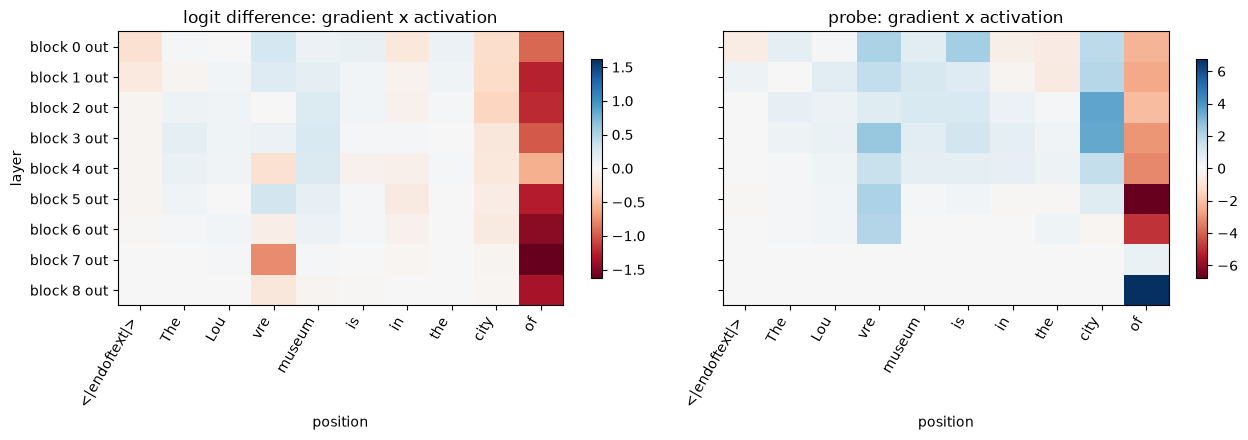

In [8]:
# @title Gradient x activation maps for both readouts { display-mode: "form" }
capture = [f"blocks.{layer}.hook_out" for layer in range(READ_LAYER)]
_, clean_cache = model.run_with_cache(tokens, names_filter=capture)
grads, maps = {}, {}
for name, readout in readouts.items():
    pre, _, value = backend.bwd_w_intervention(model, batch, {}, readout, capture=capture)
    grads[name] = pre
    maps[name] = torch.stack([(pre[site][0] * clean_cache[site][0]).sum(-1) for site in capture])  # [layer, position]
    print(f"{name:<17} value {value.item():+7.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (name, attribution) in zip(axes, maps.items()):
    # the color scale leaves out BOS and the last row (block READ_LAYER - 1's output, where the probe is read: its
    # last cell is the projection itself, which would wash out the rest); values beyond it saturate
    bound = attribution[:-1, 1:].abs().max().item()
    image = ax.imshow(attribution, cmap="RdBu", vmin=-bound, vmax=bound, aspect="auto")
    ax.set_title(f"{name}: gradient x activation")
    ax.set_xticks(range(len(str_tokens)), [repr(t)[1:-1] for t in str_tokens], rotation=60, ha="right")
    ax.set_xlabel("position")
    fig.colorbar(image, ax=ax, shrink=0.8)
axes[0].set_yticks(range(len(capture)), [f"block {layer} out" for layer in range(len(capture))])
axes[0].set_ylabel("layer")
plt.tight_layout()
plt.show()

**Where the two disagree.** Per layer: the cosine similarity between the two readouts' full gradients (every position
and dimension), and the position each map leans on most (BOS excluded, since its residual stream is an attention sink
of very large norm rather than prompt content).

In [9]:
# @title Per-layer agreement { display-mode: "form" }
print(f"{'layer':<16} {'gradient cosine':>15}   {'logit difference leans on':<26} {'probe leans on':<20}")
for layer, site in enumerate(capture):
    a, b = grads["logit difference"][site][0].flatten(), grads["probe"][site][0].flatten()
    cosine = torch.nn.functional.cosine_similarity(a, b, dim=0).item()
    tops = []
    for name in readouts:
        row = maps[name][layer]
        position = int(row[1:].abs().argmax()) + 1
        tops.append(f"{str_tokens[position]!r} ({row[position].item():+.2f})")
    print(f"block {layer:<2} out      {cosine:>15.3f}   {tops[0]:<26} {tops[1]:<20}")

layer            gradient cosine   logit difference leans on  probe leans on      
block 0  out                0.439   ' of' (-0.93)              ' is' (+2.32)       
block 1  out                0.471   ' of' (-1.26)              ' of' (-2.56)       
block 2  out                0.328   ' of' (-1.21)              ' city' (+3.57)     
block 3  out                0.350   ' of' (-0.99)              ' city' (+3.48)     
block 4  out                0.374   ' of' (-0.57)              ' of' (-3.25)       
block 5  out                0.475   ' of' (-1.27)              ' of' (-6.77)       
block 6  out                0.516   ' of' (-1.47)              ' of' (-4.89)       
block 7  out                0.490   ' of' (-1.62)              ' of' (+0.44)       
block 8  out                0.121   ' of' (-1.34)              ' of' (+16.55)      


**Reading it.** The two maps share their strongest column, the last position, where both readouts are read. Away
from it they differ: the probe draws credit from `city` in the early blocks and from `vre` through the middle ones,
where the logit difference's map is faint, and the logit difference's one strong off-diagonal cell, `vre` at block 7,
has no counterpart in the probe's. Their full gradients agree only partly (cosines of 0.3 to 0.5 through the middle
layers), and least at `READ`, where the probe's gradient is just the probe direction at the last position: the
derivative of the projection itself. The logit difference also depends on everything blocks `READ_LAYER` to 11 and the
unembedding do with the residual stream, and the probe stops at `READ`.

So a probe that tracks the answer is not a stand-in for it: the same prompt supports both, through partly different
routes. The probe is also a rough one. It separates the prompts the model answers confidently, but two London prompts,
the two the model is least sure of (`Trafalgar Square`, and `The Tower Bridge`, which it completes with Toronto),
project on the Paris side.

## 2. A latent feature readout

**Question.** The SAE at `READ` decomposes the residual stream into sparse features. Is there a Paris feature, and
which earlier positions does it read from?

**Selecting the feature.** The feature whose mean activation at the last token most separates the Paris prompts
from the London prompts, among those active on the target. Its activation across all ten prompts is printed as a check
that it is Paris-selective, not merely large.

**The readout.** With the SAE attached (`latent_model_handles`), a readout may read its stage values under the hook
it is attached at: `<hook>.hook_sae_acts_post` is the feature activations. Here the readout is one feature's activation
at the last token.

In [10]:
# @title Select a Paris-selective feature and read it out { display-mode: "form" }
FEATURE_SITE = f"blocks.{READ_LAYER}.hook_resid_pre.hook_sae_acts_post"
with torch.no_grad():
    acts = {p: sae.encode(last_token_residual(p)[None])[0] for p in PARIS_PROMPTS + LONDON_PROMPTS}
    paris_acts = torch.stack([acts[p] for p in PARIS_PROMPTS if p != TARGET]).mean(0)
    london_acts = torch.stack([acts[p] for p in LONDON_PROMPTS]).mean(0)
FEATURE = int(((paris_acts - london_acts) * (acts[TARGET] > 0)).argmax())
print(f"feature {FEATURE} at {sae.cfg.metadata.hook_name}, activation at the last token (target marked *):")
for prompt in PARIS_PROMPTS + LONDON_PROMPTS:
    print(f"  {'*' if prompt == TARGET else ' '} {prompt:<40} {acts[prompt][FEATURE].item():6.2f}")


def feature_activation(logits, activations):
    return activations[FEATURE_SITE][:, -1, FEATURE].sum()


feature_readout = Readout(feature_activation, sites=(FEATURE_SITE,))

feature 22250 at blocks.9.hook_resid_pre, activation at the last token (target marked *):
    The Eiffel Tower is in the city of         0.00
  * The Louvre museum is in the city of        8.53
    Notre-Dame cathedral is in the city of     4.64
    The Arc de Triomphe is in the city of      4.78
    The Champs-Élysées is in the city of      12.72
    Big Ben is in the city of                  0.00
    Buckingham Palace is in the city of        0.00
    Westminster Abbey is in the city of        0.00
    Trafalgar Square is in the city of         0.00
    The Tower Bridge is in the city of         0.00


The feature is zero on every London prompt, and also on the Eiffel Tower prompt: the one Paris prompt the model does not
answer with Paris (its logit difference above is slightly negative). A feature that is off exactly where the model
fails to recall Paris is a good candidate for part of how it recalls Paris.

**The gradient map, and its control.** At the input of block `ABLATION_LAYER`, the gradient predicts, to first order,
what mean-ablating each position would do to the feature: replacing the residual stream $h_p$ at position $p$ with
the mean $\bar h$ over every position of all ten prompts changes the feature by about
$g_p^\top (\bar h - h_p)$, where $g_p$ is the feature's gradient there. The control runs each ablation forward and
measures the change.

The comparison is only meaningful where the prediction is a fair one, so BOS is reported but left out of the ranking:
mean-ablating the attention sink takes the model far outside anything the mean represents, and both the prediction
and any conclusion drawn from it would be about that, not about the prompt.

In [11]:
# @title Predicted versus measured effect of ablating each position { display-mode: "form" }
ABLATION_SITE = f"blocks.{ABLATION_LAYER}.hook_in"
pre, _, feature_value = backend.bwd_w_intervention(
    model, batch, {}, feature_readout, capture=[ABLATION_SITE], latent_model_handles=module.sae_handles
)
with torch.no_grad():
    mean_residual = torch.cat(
        [
            model.run_with_cache(model.to_tokens(p), names_filter=[ABLATION_SITE])[1][ABLATION_SITE][0, 1:]
            for p in PARIS_PROMPTS + LONDON_PROMPTS
        ]
    ).mean(0)
    clean_residual = model.run_with_cache(tokens, names_filter=[ABLATION_SITE])[1][ABLATION_SITE][0]
predicted = (pre[ABLATION_SITE][0] * (mean_residual - clean_residual)).sum(-1)


def feature_after_ablating(positions):
    applied = []

    def ablate(activation, hook):
        applied.append(hook.name)
        activation = activation.clone()
        activation[:, positions] = mean_residual
        return activation

    with torch.no_grad(), model.hooks(fwd_hooks=[(ABLATION_SITE, ablate)]):
        _, cache = model.run_with_cache(tokens, names_filter=[READ])
    assert applied, f"the ablation hook at {ABLATION_SITE} never ran"
    return sae.encode(cache[READ][0, -1:])[0, FEATURE].item()


clean_value = feature_after_ablating([])
assert abs(clean_value - feature_value.item()) < 1e-3, "the SAE read directly and the readout disagree"
measured = torch.tensor([feature_after_ablating([p]) - clean_value for p in range(len(str_tokens))])
print(f"feature {FEATURE} on the target: {clean_value:.3f}\n")
print(f"{'position':<16} {'predicted':>10} {'measured':>10}")
for p, token in enumerate(str_tokens):
    note = "   (BOS: reported, not ranked)" if p == 0 else ""
    print(f"{token!r:<16} {predicted[p].item():>+10.3f} {measured[p].item():>+10.3f}{note}")

feature 22250 on the target: 8.528

position          predicted   measured
'<|endoftext|>'      -0.107     -8.528   (BOS: reported, not ranked)
'The'                +0.709     +0.061
' Lou'               +0.333     -1.228
'vre'                -2.627     -6.110
' museum'            +1.008     +0.746
' is'                +0.088     -0.102
' in'                -1.614     -1.208
' the'               +0.331     -0.152
' city'              +6.056     +3.188
' of'                -0.613     -5.286


In [12]:
# @title Does the gradient's ranking survive forward ablation? { display-mode: "form" }
ranked = sorted(range(1, len(str_tokens)), key=lambda p: predicted[p].item())  # most negative prediction first


def ranks(values):
    return torch.argsort(torch.argsort(values)).float()


x, y = ranks(predicted[1:]), ranks(measured[1:])
spearman = torch.corrcoef(torch.stack([x, y]))[0, 1].item()
sign_agreement = (predicted[1:].sign() == measured[1:].sign()).float().mean().item()
print(f"rank correlation, predicted vs measured (BOS excluded): {spearman:+.2f}")
print(f"sign agreement: {sign_agreement:.0%}\n")
K = 2
for label, positions in (("predicted to lower it most", ranked[:K]), ("predicted to raise it most", ranked[-K:])):
    change = feature_after_ablating(positions) - clean_value
    print(f"ablating the {K} positions {label} {[str_tokens[p] for p in positions]}: feature changes by {change:+.2f}")

rank correlation, predicted vs measured (BOS excluded): +0.85
sign agreement: 67%

ablating the 2 positions predicted to lower it most ['vre', ' in']: feature changes by -6.29


ablating the 2 positions predicted to raise it most [' museum', ' city']: feature changes by +4.04


**Reading it.** The gradient's ranking survives the forward check where it matters most: ablating the two positions it
predicts lower the feature most (`vre`, the end of "Louvre", and `in`) does lower it, sharply, and ablating the two it
predicts raise it most does raise it. The ranks agree well overall. The magnitudes do not: a single-position mean
ablation is a large change, and the feature passes through the SAE's nonlinearity, so the first-order prediction
misjudges sizes (at the last position by almost a factor of ten), and it gets the sign wrong at a few positions whose
predicted effect is small. That is the reason for the control. A gradient map is a ranking hypothesis about small
changes, and a forward ablation is the experiment that says how far it carries.

## 3. A gradient edit, read correctly

A gradient edit changes the gradient at one site while the backward pass runs, so every site upstream sees the edited
gradient. The forward pass is not edited: the readout's value is the same with and without the edit. Two readings,
which the [intervention APIs page](https://interpretune.org/en/latest/interpretune_intervention_apis.html) states:

- **An `add` edit is a change of readout.** Adding a vector $v$ to the gradient at site $s$ gives every site upstream
  the gradient of $R + \langle v, h_s \rangle$: the readout $R$ plus a linear term in the activation $h_s$, with $v$
  held constant.
- **A `replace` (zeroing), `scale`, `project` or `reject` edit is not.** It changes which paths the gradient may
  take past $s$, not which scalar is differentiated. Across inputs, the edited gradient is in general not the gradient
  of any single function, so no readout reproduces it.

First, the `add` reading, checked numerically: an `add` edit at the last position of block `EDIT_LAYER`'s output,
under the logit difference, against the logit difference plus that linear term as a readout of its own.

In [13]:
# @title An add edit equals a linear term added to the readout { display-mode: "form" }
EDIT_SITE, UPSTREAM = f"blocks.{EDIT_LAYER}.hook_out", "blocks.1.hook_out"
v = 0.5 * direction
add_edit = {EDIT_SITE: {"intervention_tensor": v, "op": "add", "scale_factor": 1.0, "position_scope": "last_token"}}
_, edited, _ = backend.bwd_w_intervention(model, batch, add_edit, readouts["logit difference"], capture=[UPSTREAM])


def plus_linear_term(logits, activations):
    return logit_difference(logits, activations) + (activations[EDIT_SITE][:, -1] @ v).sum()


as_readout_change, _, _ = backend.bwd_w_intervention(
    model, batch, {}, Readout(plus_linear_term, sites=(EDIT_SITE,)), capture=[UPSTREAM]
)
gap = (edited[UPSTREAM] - as_readout_change[UPSTREAM]).abs().max().item()
print(f"largest difference at {UPSTREAM}: {gap:.2e} (gradient entries up to {edited[UPSTREAM].abs().max().item():.2f})")

largest difference at blocks.1.hook_out: 1.49e-07 (gradient entries up to 0.29)


Now an edit that is not a change of readout: **reject the probe direction from the gradient** at the last position of
block `EDIT_LAYER`'s output (venngram's `reject` op; `project` would keep only that component instead). Whatever
reaches earlier sites afterwards is what travels past that site along every other direction. Comparing it with the
unedited gradient asks: how much of what each readout draws from upstream passes through the probe direction there?

This runs through the analysis op, `it.model_bwd_intervention`, with the readout passed as its `readout` input, once
per readout. The op stores both gradients and `intervention_grad_position_effect`, the largest change in any captured
gradient at each position.

In [14]:
# @title Reject the probe direction from the gradient, under each readout { display-mode: "form" }
from interpretune import AnalysisCfg
from interpretune.analysis.ops.base import AnalysisBatch
from interpretune.runners.analysis import maybe_init_analysis_cfg
from transformers import BatchEncoding

reject_edit = {EDIT_SITE: {"intervention_tensor": direction, "op": "reject", "position_scope": "last_token"}}
all_readouts = {**readouts, "feature": feature_readout}
print(f"edit: reject the probe direction at {EDIT_SITE}, last position; gradients captured at {UPSTREAM}\n")
for name, readout in all_readouts.items():
    run_inputs = {"interventions": reject_edit, "grad_capture": [UPSTREAM], "readout": readout}
    if name == "feature":
        run_inputs["use_latent_models"] = True  # the feature readout reads the attached SAE
    cfg = AnalysisCfg(target_op=it.model_bwd_intervention, run_inputs=run_inputs, ignore_manual=True)
    maybe_init_analysis_cfg(module, cfg)
    result = it.model_bwd_intervention(module, AnalysisBatch(), BatchEncoding(batch), 0)
    shape = (len(str_tokens), model.cfg.d_model)
    pre_grad = torch.as_tensor(result.pre_intervention_grad_values).reshape(shape)
    post_grad = torch.as_tensor(result.post_intervention_grad_values).reshape(shape)
    kept = (post_grad.norm() / pre_grad.norm()).item()
    effect = result.intervention_grad_position_effect[0]
    most = int(effect.argmax())
    print(
        f"{name:<17} readout {result.bwd_intervention_metric.item():+8.3f}   "
        f"gradient kept at {UPSTREAM}: {kept:5.1%}   "
        f"largest change at {str_tokens[most]!r} ({effect[most].item():.3f})"
    )

edit: reject the probe direction at blocks.5.hook_out, last position; gradients captured at blocks.1.hook_out



logit difference  readout   +4.785   gradient kept at blocks.1.hook_out: 96.9%   largest change at ' is' (0.020)


probe             readout  +16.555   gradient kept at blocks.1.hook_out: 70.1%   largest change at ' is' (0.416)


feature           readout   +8.528   gradient kept at blocks.1.hook_out: 92.0%   largest change at ' is' (0.247)


**Reading it.** Each readout's value is the one it had above, since the forward pass is untouched. What moves is the
gradient upstream, and by how much depends on the readout. With the probe direction closed off at block `EDIT_LAYER`'s
last position, the probe's gradient at block 1 keeps about 70% of its norm, the logit difference's nearly all of it, and
the Paris feature's lands in between. That is the expected shape: the probe reads that direction, later in the same
residual stream, while the logit difference reads it only as far as the rest of the model passes it on. The change is
not confined to the last position. The edit is at the last position, but the gradient it leaves there flows back through
attention into the positions that position read from.

That is a statement about paths: "with the probe direction at block `EDIT_LAYER`'s last position closed off, this
much of each readout's gradient still reaches block 1". It is not a statement about a different scalar, which is the
`add` case only.

## Where next

- The [intervention APIs page](https://interpretune.org/en/latest/interpretune_intervention_apis.html) documents
  readouts, gradient interventions and the edit readings above.
- A readout declared in a venngram book, alongside this callable form, will follow once interpretune executes
  declared readouts (#1024).